# ChebND 
## 1-Dimensional Interpolation

In [1]:
from chebND.interp1d import ChebyshevInterpolant1D, compute_chebyshev_coefficients_1d
from chebND.clenshaw import clenshaw_1d
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import dct

In [2]:
# Define function and domain
f = lambda x: np.exp(-x**2)

In [3]:
a = -2
b = 2
N = 20  

In [4]:
interp = ChebyshevInterpolant1D(f, a=a, b=b, N=N)

In [5]:
x_test = np.linspace(-2, 2, 1000)
y_interp = interp.evaluate(x_test)
y_vals = f(x_test)

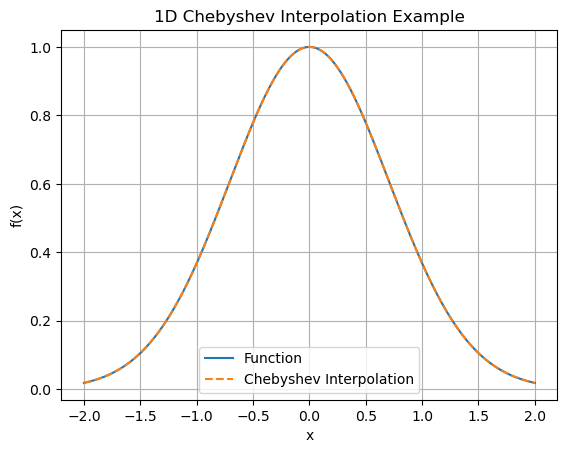

In [6]:
# Plotting the results
plt.plot(x_test, y_vals, label='Function')
plt.plot(x_test, y_interp, label='Chebyshev Interpolation', linestyle='--')
plt.legend()
plt.title('1D Chebyshev Interpolation Example')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.grid()
plt.show()

In [7]:
estAbsErr = interp.absolute_error()
estRelErr = interp.relative_error()

print(f"Estimated Absolute Error: {estAbsErr}")
print(f"Estimated Relative Error: {estRelErr}")

Estimated Absolute Error: 8.166033222511971e-07
Estimated Relative Error: 1.896701859100013e-06


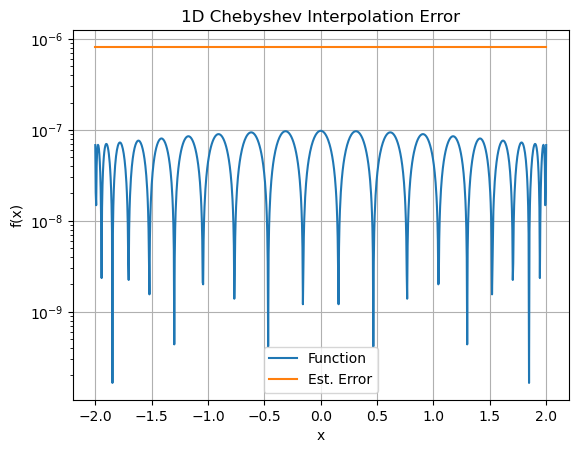

In [8]:
# Plotting the results
plt.plot(x_test, abs(y_vals - y_interp), label='Function')
plt.plot(x_test, np.ones_like(x_test) * estAbsErr, label='Est. Error')
plt.legend()
plt.title('1D Chebyshev Interpolation Error')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.yscale('log')
plt.grid()
plt.show()

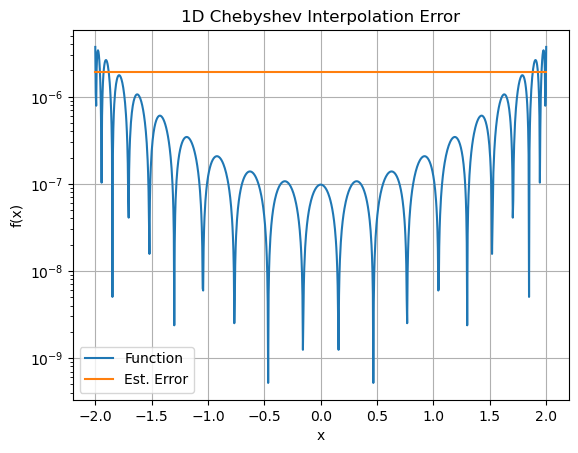

In [9]:
# Plotting the results
plt.plot(x_test, abs((y_vals - y_interp)/y_vals), label='Function')
plt.plot(x_test, np.ones_like(x_test) * estRelErr, label='Est. Error')
plt.legend()
plt.title('1D Chebyshev Interpolation Error')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.yscale('log')
plt.grid()
plt.show()

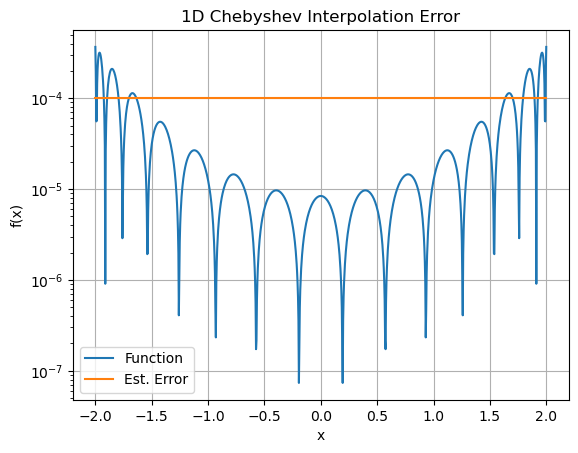

In [17]:
delta = 1e-4
interp.optimize(rel_tol=delta)
y_interp = interp.evaluate(x_test)
# Plotting the results
plt.plot(x_test, abs((y_vals - y_interp)/y_vals), label='Function')
plt.plot(x_test, np.ones_like(x_test) * delta, label='Est. Error')
plt.legend()
plt.title('1D Chebyshev Interpolation Error')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.yscale('log')
plt.grid()
plt.show()